# Task 1 — Superstore Retail Sales EDA
**Datheon Data Analytics & Power BI Internship**  
**Environment:** VS Code + Python Jupyter Notebook  
**Goal:** Clean and explore sales records, analyse monthly seasonality and category/region/segment performance, investigate discounts and profit, and communicate five executive recommendations.

**Dataset caution:** This provided CSV combines multiple Superstore tables. Not all CSV rows represent sales. We explicitly isolate the sales rows and document why.

## 1. Load libraries and locate the actual CSV

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")

candidates = [Path("data/raw/superstore_sales.csv"), Path("../data/raw/superstore_sales.csv")]
csv_path = next((p.resolve() for p in candidates if p.is_file()), None)
if csv_path is None:
    raise FileNotFoundError("Could not find data/raw/superstore_sales.csv. Open the project folder in VS Code.")
root = csv_path.parents[2]
fig_dir = root / "reports" / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)
processed_dir = root / "data" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)

raw = pd.read_csv(csv_path, dtype={"Postal Code": "string"})
print("Raw dataset shape:", raw.shape)
display(raw.head())

Raw dataset shape: (10800, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164


In [2]:
# Check the number of rows and columns
print("Dataset Shape:", raw.shape)

# Check column names
print("\nColumn Names:")
print(raw.columns.tolist())

# Check data types and missing values
print("\nDataset Information:")
raw.info()

Dataset Shape: (10800, 21)

Column Names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 10800 entries, 0 to 10799
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         10800 non-null  str    
 1   Order ID       10800 non-null  str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  P

## 2. Audit dataset structure and quality

In [3]:
print("Columns:", raw.columns.tolist())
print("Data types:")
print(raw.dtypes)
print("Missing values by column:")
display(raw.isna().sum().sort_values(ascending=False).to_frame("Missing rows"))
print("Exact duplicates across ALL 10,800 mixed rows:", raw.duplicated().sum())
print("Tail sample shows extra People/Returns records:")
display(raw.iloc[9992:10003, :4])

Columns: ['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']
Data types:
Row ID               str
Order ID             str
Order Date           str
Ship Date            str
Ship Mode            str
Customer ID          str
Customer Name        str
Segment              str
Country              str
City                 str
State                str
Postal Code       string
Region               str
Product ID           str
Category             str
Sub-Category         str
Product Name         str
Sales            float64
Quantity         float64
Discount         float64
Profit           float64
dtype: object
Missing values by column:


,Missing rows
Postal Code,817
Ship Mode,806
Ship Date,806
Customer ID,806
Order Date,806
Product ID,806
Category,806
Segment,806
Customer Name,806
Country,806


Exact duplicates across ALL 10,800 mixed rows: 504
Tail sample shows extra People/Returns records:


,Row ID,Order ID,Order Date,Ship Date
9992,9993,CA-2018-121258,2/26/2018,3/3/2018
9993,9994,CA-2018-119914,5/4/2018,5/9/2018
9994,Person,Region,NaN,NaN
9995,Anna Andreadi,West,NaN,NaN
9996,Chuck Magee,East,NaN,NaN
9997,Kelly Williams,Central,NaN,NaN
9998,Cassandra Brandow,South,NaN,NaN
9999,Returned,Order ID,NaN,NaN
10000,Yes,CA-2015-100762,NaN,NaN
10001,Yes,CA-2015-100762,NaN,NaN


## 3. Separate the real sales table and clean data

In [4]:
valid_row_id = pd.to_numeric(raw["Row ID"], errors="coerce").notna()
orders = raw.loc[valid_row_id & raw["Order Date"].notna() & raw["Sales"].notna()].copy()

orders["Row ID"] = orders["Row ID"].astype(int)
orders["Order Date"] = pd.to_datetime(orders["Order Date"], format="%m/%d/%Y", errors="coerce")
orders["Ship Date"] = pd.to_datetime(orders["Ship Date"], format="%m/%d/%Y", errors="coerce")
for col in ["Sales", "Profit", "Discount", "Quantity"]:
    orders[col] = pd.to_numeric(orders[col], errors="coerce")

# Only remove EXACT duplicate sales records. Repeated Order IDs are normal line items.
before_dedup = len(orders)
orders = orders.drop_duplicates().copy()
assert orders["Order Date"].notna().all(), "Unexpected date parsing problem"
assert orders[["Sales", "Profit", "Discount", "Quantity"]].notna().all().all()

orders["Year"] = orders["Order Date"].dt.year
orders["Year-Month"] = orders["Order Date"].dt.to_period("M").dt.to_timestamp()
orders["Calendar Month"] = orders["Order Date"].dt.month
orders["Profit Margin"] = np.where(orders["Sales"].ne(0), orders["Profit"] / orders["Sales"], np.nan)

print("Total raw CSV rows:", len(raw))
print("Non-sales rows excluded:", len(raw) - before_dedup)
print("Exact duplicate sales rows removed:", before_dedup - len(orders))
print("Sales line items remaining:", len(orders))
print("Unique orders:", orders["Order ID"].nunique())
print("Missing postcodes retained:", orders["Postal Code"].isna().sum())
print("Date range:", orders["Order Date"].min().date(), "to", orders["Order Date"].max().date())

orders.to_csv(processed_dir / "superstore_orders_cleaned.csv", index=False)
display(orders.head(3))

Total raw CSV rows: 10800
Non-sales rows excluded: 806
Exact duplicate sales rows removed: 0
Sales line items remaining: 9994
Unique orders: 5009
Missing postcodes retained: 11
Date range: 2015-01-03 to 2018-12-30


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Year,Year-Month,Calendar Month,Profit Margin
0,1,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Bookcases,Bush Somerset Collection Bookcase,261.96,2.0,0.0,41.9136,2017,2017-11-01,11,0.16
1,2,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3.0,0.0,219.5820,2017,2017-11-01,11,0.30
2,3,CA-2017-138688,2017-06-12,2017-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2.0,0.0,6.8714,2017,2017-06-01,6,0.47


## 4. Executive performance KPIs

In [5]:
total_sales = orders["Sales"].sum()
total_profit = orders["Profit"].sum()
unique_orders = orders["Order ID"].nunique()
unique_customers = orders["Customer ID"].nunique()
profit_margin = total_profit / total_sales

print(f"Total sales: {total_sales:,.2f}")
print(f"Total profit: {total_profit:,.2f}")
print(f"Profit margin: {profit_margin:.2%}")
print(f"Distinct orders: {unique_orders:,}")
print(f"Distinct customers: {unique_customers:,}")

Total sales: 2,297,200.86
Total profit: 286,397.02
Profit margin: 12.47%
Distinct orders: 5,009
Distinct customers: 793


## 5. Monthly sales trend and seasonality

First five months:


,Year-Month,Total_Sales,Total_Profit,Total_Orders
0,2015-01-01,14236.895,2450.1907,32
1,2015-02-01,4519.892,862.3084,28
2,2015-03-01,55691.009,498.7299,71
3,2015-04-01,28295.345,3488.8352,66
4,2015-05-01,23648.287,2738.7096,69


Last five months:


,Year-Month,Total_Sales,Total_Profit,Total_Orders
43,2018-08-01,63120.8880,9040.9557,111
44,2018-09-01,87866.6520,10991.5556,226
45,2018-10-01,77776.9232,9275.2755,147
46,2018-11-01,118447.8250,9690.1037,261
47,2018-12-01,83829.3188,8483.3468,224


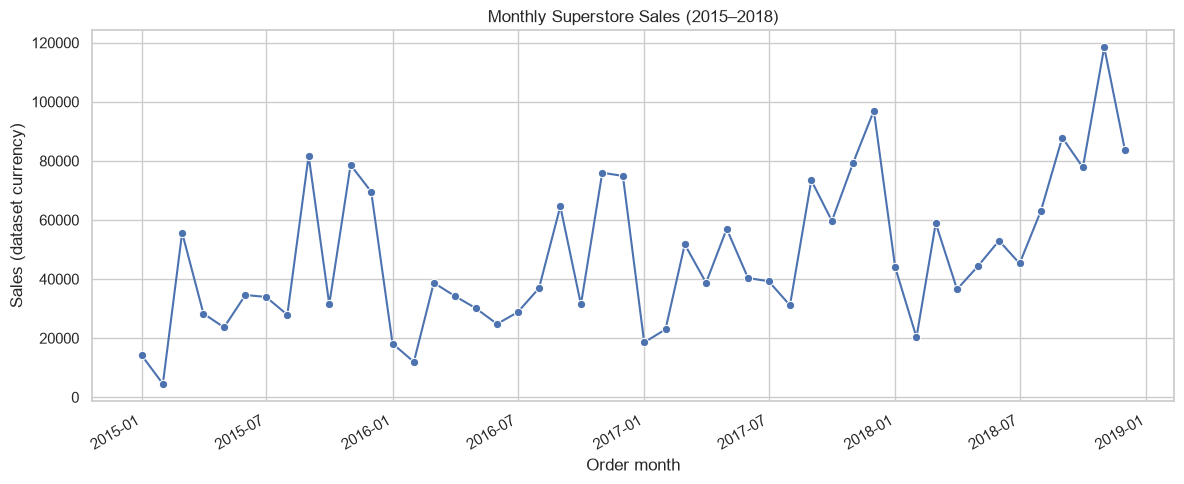

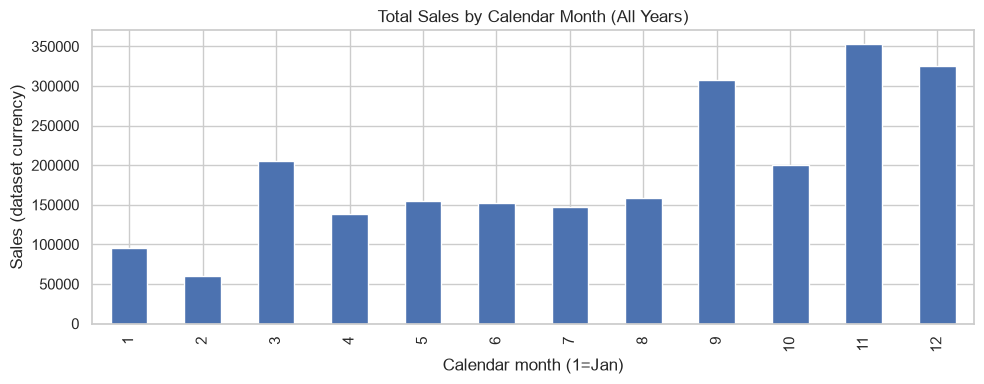

In [6]:
monthly = orders.groupby("Year-Month", as_index=False).agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
monthly = monthly.sort_values("Year-Month")


monthly_analysis = orders.groupby("Year-Month").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order ID", "nunique")
).reset_index()

# Sort months chronologically
monthly_analysis = monthly_analysis.sort_values("Year-Month")

# Display the first and last five months
print("First five months:")
display(monthly_analysis.head())

print("Last five months:")
display(monthly_analysis.tail())
fig, ax = plt.subplots(figsize=(12, 5))
sns.lineplot(data=monthly, x="Year-Month", y="Sales", marker="o", ax=ax)
ax.set(title="Monthly Superstore Sales (2015–2018)", xlabel="Order month", ylabel="Sales (dataset currency)")
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(fig_dir / "01_monthly_sales_trend.png", dpi=160)
plt.show()

month_of_year = orders.groupby("Calendar Month")["Sales"].sum().reindex(range(1, 13))
fig, ax = plt.subplots(figsize=(10, 4))
month_of_year.plot(kind="bar", ax=ax)
ax.set(title="Total Sales by Calendar Month (All Years)", xlabel="Calendar month (1=Jan)", ylabel="Sales (dataset currency)")
fig.tight_layout()
fig.savefig(fig_dir / "02_calendar_month_sales.png", dpi=160)
plt.show()

## 6. Category, region and customer segment performance

CATEGORY


,Sales,Profit,Line_Items,Profit Margin %
Category,,,,
Technology,836154.03,145454.95,1847,17.40
Furniture,741999.80,18451.27,2121,2.49
Office Supplies,719047.03,122490.80,6026,17.04


REGION


,Sales,Profit,Line_Items,Profit Margin %
Region,,,,
West,725457.82,108418.45,3203,14.94
East,678781.24,91522.78,2848,13.48
Central,501239.89,39706.36,2323,7.92
South,391721.90,46749.43,1620,11.93


CUSTOMER SEGMENT


,Sales,Profit,Line_Items,Profit Margin %
Segment,,,,
Consumer,1161401.34,134119.21,5191,11.55
Corporate,706146.37,91979.13,3020,13.03
Home Office,429653.15,60298.68,1783,14.03


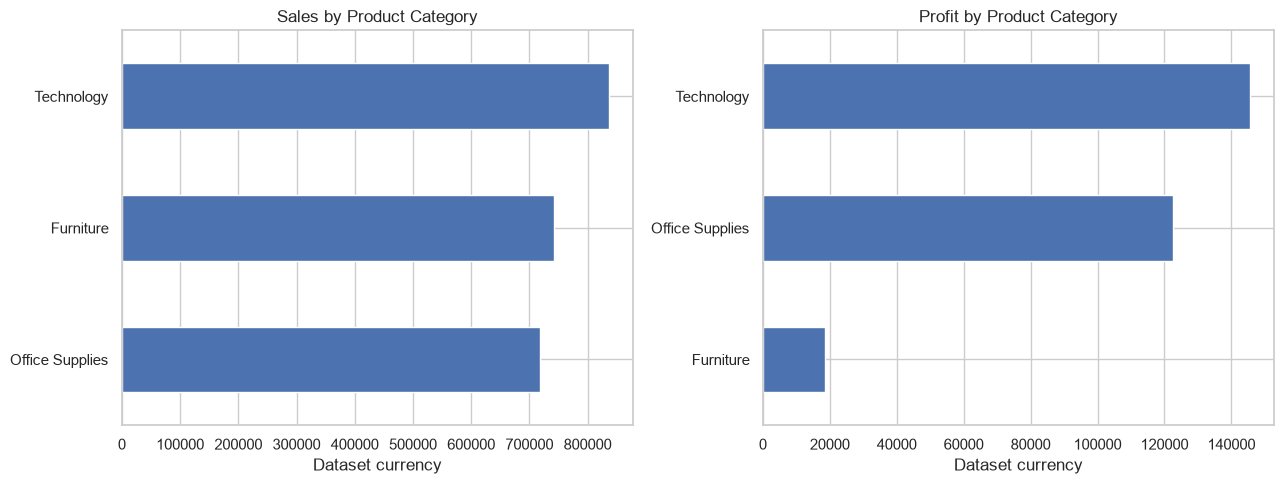

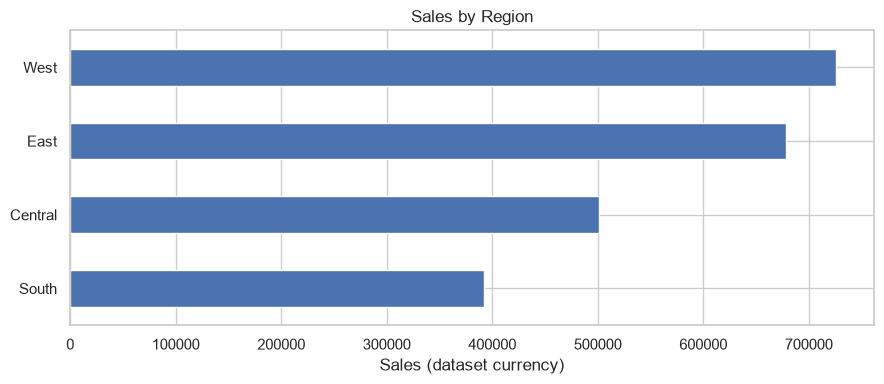

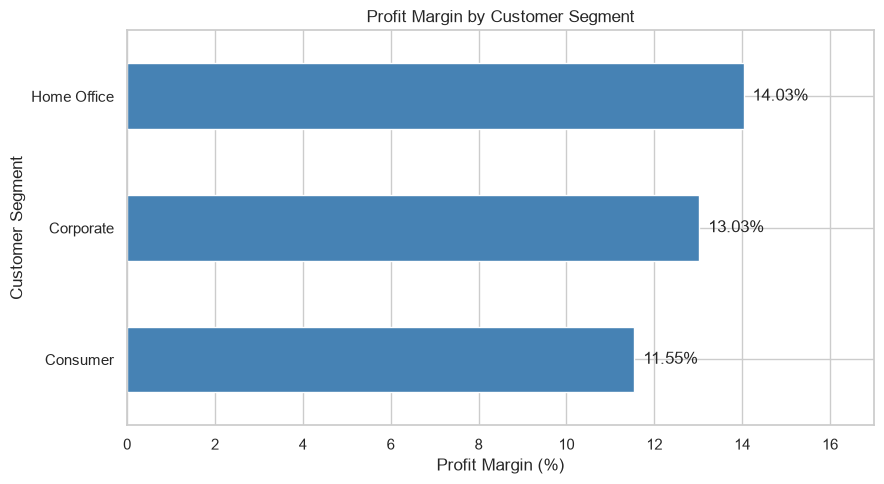

In [7]:
def group_performance(column):
    grouped = orders.groupby(column).agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"),
                                        Line_Items=("Order ID", "size"))
    grouped["Profit Margin %"] = 100 * grouped["Profit"] / grouped["Sales"]
    return grouped.sort_values("Sales", ascending=False)

category = group_performance("Category")
region = group_performance("Region")
segment = group_performance("Segment")
print("CATEGORY")
display(category.round(2))
print("REGION")
display(region.round(2))
print("CUSTOMER SEGMENT")
display(segment.round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
category["Sales"].sort_values().plot(kind="barh", ax=axes[0], title="Sales by Product Category")
category["Profit"].sort_values().plot(kind="barh", ax=axes[1], title="Profit by Product Category")
for ax in axes:
    ax.set(xlabel="Dataset currency", ylabel="")
fig.tight_layout()
fig.savefig(fig_dir / "03_category_sales_profit.png", dpi=160)
plt.show()

fig, ax = plt.subplots(figsize=(9, 4))
region["Sales"].sort_values().plot(kind="barh", ax=ax)
ax.set(title="Sales by Region", xlabel="Sales (dataset currency)", ylabel="")
fig.tight_layout()
fig.savefig(fig_dir / "04_region_sales.png", dpi=160)
plt.show()

# Customer Segment Profit Margin Chart

fig, ax = plt.subplots(figsize=(9, 5))

segment["Profit Margin %"].sort_values().plot(
    kind="barh",
    ax=ax,
    color="steelblue"
)

ax.set_title("Profit Margin by Customer Segment")
ax.set_xlabel("Profit Margin (%)")
ax.set_ylabel("Customer Segment")

# Display values on bars
for bar in ax.patches:
    ax.text(
        bar.get_width() + 0.2,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.2f}%",
        va="center"
    )

ax.set_xlim(0, 17)

plt.tight_layout()

# Save chart to project folder
fig.savefig(
    fig_dir / "07_customer_segment_margin.png",
    dpi=160
)

plt.show()

## 7. Customer purchase volume

In [8]:
customer_summary = orders.groupby("Customer ID").agg(
    Distinct_Orders=("Order ID", "nunique"),
    Total_Spend=("Sales", "sum"),
    Total_Profit=("Profit", "sum")
).sort_values("Total_Spend", ascending=False)
display(customer_summary.head(10).round(2))
print("Median distinct orders per customer:", customer_summary["Distinct_Orders"].median())

,Distinct_Orders,Total_Spend,Total_Profit
Customer ID,,,
SM-20320,5,25043.05,-1980.74
TC-20980,5,19052.22,8981.32
RB-19360,6,15117.34,6976.10
TA-21385,4,14595.62,4703.79
AB-10105,10,14473.57,5444.81
KL-16645,12,14175.23,806.86
SC-20095,9,14142.33,5757.41
HL-15040,6,12873.30,5622.43
SE-20110,11,12209.44,2650.68


Median distinct orders per customer: 6.0


## 8. Discounts and profit sensitivity

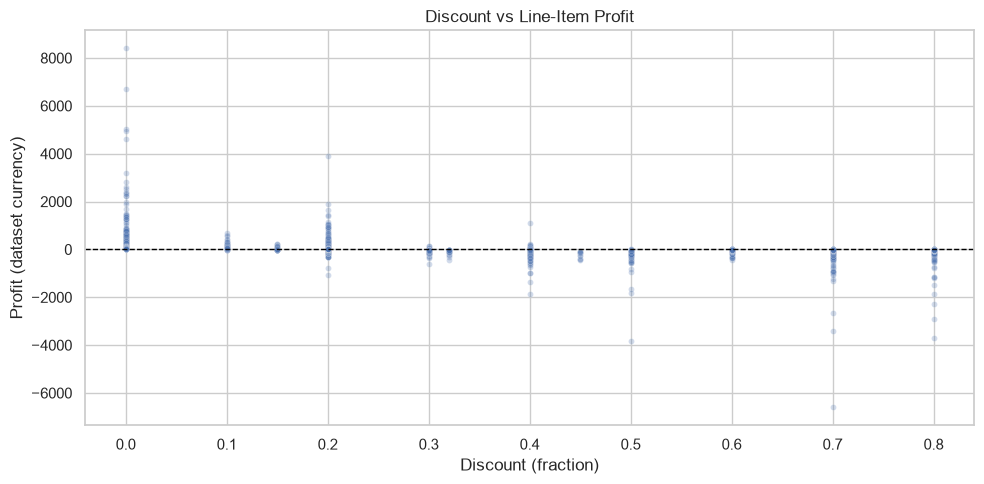

,Sales,Profit,Line_Items,Profit Margin %
Discount Band,,,,
0%,1087908.47,320987.60,4798,29.51
>0% to 20%,846522.24,100785.47,3803,11.91
>20% to 40%,234137.90,-35817.47,460,-15.30
>40% to 60%,71048.21,-28944.19,215,-40.74
>60% to 100%,57584.04,-70614.40,718,-122.63


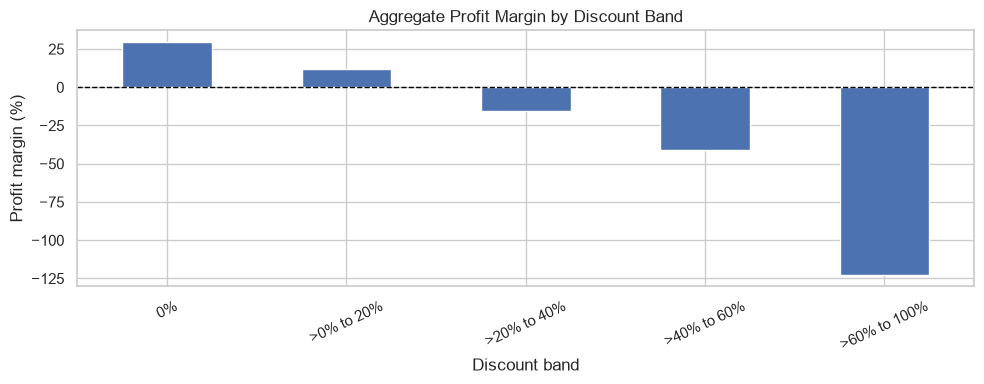

In [9]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.scatterplot(data=orders, x="Discount", y="Profit", alpha=0.25, s=18, ax=ax)
ax.axhline(0, color="black", linestyle="--", linewidth=1)
ax.set(title="Discount vs Line-Item Profit", xlabel="Discount (fraction)", ylabel="Profit (dataset currency)")
fig.tight_layout()
fig.savefig(fig_dir / "05_discount_profit_scatter.png", dpi=160)
plt.show()

orders["Discount Band"] = pd.cut(
    orders["Discount"],
    bins=[-0.001, 0, 0.2, 0.4, 0.6, 1.0],
    labels=["0%", ">0% to 20%", ">20% to 40%", ">40% to 60%", ">60% to 100%"],
    include_lowest=True
)
discount_summary = orders.groupby("Discount Band", observed=True).agg(
    Sales=("Sales", "sum"), Profit=("Profit", "sum"), Line_Items=("Profit", "size")
)
discount_summary["Profit Margin %"] = 100 * discount_summary["Profit"] / discount_summary["Sales"]
display(discount_summary.round(2))

fig, ax = plt.subplots(figsize=(10, 4))
discount_summary["Profit Margin %"].plot(kind="bar", ax=ax)
ax.axhline(0, color="black", linestyle="--", linewidth=1)
ax.set(title="Aggregate Profit Margin by Discount Band", xlabel="Discount band", ylabel="Profit margin (%)")
ax.tick_params(axis="x", rotation=25)
fig.tight_layout()
fig.savefig(fig_dir / "06_discount_margin_bands.png", dpi=160)
plt.show()

## 9. Additional breakdown: yearly results and low-profit product groups

In [10]:
yearly = orders.groupby("Year").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
yearly["Profit Margin %"] = 100 * yearly["Profit"] / yearly["Sales"]
subcategories = group_performance("Sub-Category").sort_values("Profit")
print("ANNUAL PERFORMANCE")
display(yearly.round(2))
print("LOWEST-PROFIT PRODUCT SUB-CATEGORIES")
display(subcategories.head(5).round(2))

ANNUAL PERFORMANCE


,Sales,Profit,Profit Margin %
Year,,,
2015,484247.50,49543.97,10.23
2016,470532.51,61618.60,13.10
2017,609205.60,81795.17,13.43
2018,733215.26,93439.27,12.74


LOWEST-PROFIT PRODUCT SUB-CATEGORIES


,Sales,Profit,Line_Items,Profit Margin %
Sub-Category,,,,
Tables,206965.53,-17725.48,319,-8.56
Bookcases,114880.00,-3472.56,228,-3.02
Supplies,46673.54,-1189.10,190,-2.55
Fasteners,3024.28,949.52,217,31.40
Machines,189238.63,3384.76,115,1.79


## 10. Key Findings and Business Insights

After cleaning and analysing the Superstore Sales dataset, I identified five main findings.

### 1. Overall Sales and Profit Performance

The dataset contains 9,994 sales records from 2015 to 2018, with 5,009 unique orders and 793 customers.

During these four years, the business generated approximately **2.30 million in sales** and **286,397 in profit**, with an overall profit margin of **12.47%**.

One thing I learned from this analysis is that looking at sales alone does not give the complete picture. Profit and profit margin are also important when measuring business performance.

### 2. Product Category Performance

Technology performed the best in terms of both sales and profit, generating approximately **836,154 in sales** and **145,455 in profit**.

However, I noticed that Furniture generated around **742,000 in sales** but had a very low profit margin of **2.49%**.

Looking further into the sub-categories, Tables and Bookcases were both making losses.

**My suggestion:** The business should investigate Furniture pricing, discounts and costs to understand why these products are less profitable.

### 3. Regional and Customer Segment Performance

The West region had the highest sales and profit, generating approximately **725,458 in sales** and **108,418 in profit**.

The Central region had the lowest profit margin at **7.92%**, even though its sales were higher than the South region.

When I analysed customer segments, I found that Consumers generated the highest total sales, but Home Office customers had the highest profit margin at **14.03%**.

**My suggestion:** It would be useful to investigate why some regions and customer segments perform better than others, especially by comparing their products and discount patterns.

### 4. Monthly Sales Trends

The monthly sales analysis showed that sales generally increased over the four-year period, although there were some ups and downs.

November 2018 recorded the highest monthly sales at approximately **118,448**.

I also noticed that November had the highest combined sales when comparing calendar months across all four years.

**My suggestion:** The business could use these patterns to help plan inventory, staffing and promotions during busier months. More data would help confirm whether these patterns are consistent over time.

### 5. Discounts and Profitability

This was one of the most interesting findings for me.

Sales without discounts had a profit margin of **29.51%**, while sales with discounts above 20% showed negative profit margins across all the higher discount groups.

The highest discount group, above 60%, had a profit margin of **-122.63%**.

This suggests that higher discounts are associated with lower profitability in this dataset, although discounts may not be the only reason for the losses.

**My suggestion:** The business should review heavily discounted products and compare their costs and profits before making changes to discount policies.

---

### What I Learned from This Project

Through this project, I practised using Python and Pandas to clean and explore data. I learned how to identify missing values, handle different data types, group data and calculate business metrics.

I also created visualisations using Matplotlib and Seaborn to understand sales trends and profitability.

The biggest thing I learned was that **high sales do not always mean high profit**. Looking at different categories, regions and discount levels helped me understand how data analysis can identify business problems and support better decisions.

## 11. Limitations and submission checklist

- The CSV merges actual sales with separate People/Returns tables. We restricted analysis to sales rows.
- Multiple products can belong to one order; distinct orders use `Order ID.nunique()`.
- Missing postal codes are retained; they are not used to estimate geography.
- Discounts are observational and not a controlled causal test.
- Dates are parsed using the source's **month/day/year** format.

### Final checklist
- [ ] All notebook cells run successfully, with no errors.
- [ ] Saved charts appear in `reports/figures/`.
- [ ] Notebook includes at least five **Markdown** findings with numbers and recommendations.
- [ ] README explains dataset source, cleaning, code execution and limitations.
- [ ] Committed and pushed to a public GitHub repository.
- [ ] Submitted GitHub link using the Datheon Student Workspace instructions.